# Этап 2. Разведочный анализ данных

Анализ выполняется по серебряному слою, только объявления из Москвы.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
from db import connect

pd.set_option("display.width", 130, "display.max_columns", 30, "display.max_rows", 60)
FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
from matplotlib.ticker import FuncFormatter, NullFormatter

NAVY, BLUE, YELLOW, GREY = "#17358A", "#2F6FD0", "#F2C230", "#8A94A6"
COMMA = FuncFormatter(lambda v, _: f"{v:g}".replace(".", ","))
plt.rcParams.update({"font.family": "Times New Roman", "font.size": 12, "axes.spines.top": False,
                     "axes.spines.right": False, "figure.facecolor": "white", "savefig.dpi": 200,
                     "savefig.bbox": "tight"})


def sql(query, params=None):
    """Запрос к базе PostgreSQL: результат в виде таблицы pandas."""
    with connect() as conn:
        cur = conn.execute(query, params)
        return pd.DataFrame(cur.fetchall(), columns=[c.name for c in cur.description])

In [2]:
df = sql("SELECT * FROM v_offers_current WHERE in_moscow")
num = ["price", "area_total", "area_kitchen", "rooms", "floor", "floors_total", "built_year", "metro_minutes", "dist_center_km"]
df[num] = df[num].apply(pd.to_numeric)
print("Объявлений:", len(df), "столбцов:", df.shape[1])
df[["price", "area_total", "rooms", "floor", "floors_total", "built_year", "metro_minutes", "dist_center_km"]].describe().round(1).T[["count", "mean", "min", "25%", "50%", "75%", "max"]]

Объявлений: 5587 столбцов: 46


,count,mean,min,25%,50%,75%,max
price,5587.0,157733.3,28500.0,70000.0,100000.0,150000.0,8500000.0
area_total,5587.0,62.8,9.6,37.0,47.0,68.0,1000.0
rooms,5587.0,1.8,0.0,1.0,2.0,2.0,12.0
floor,5585.0,10.9,1.0,4.0,8.0,14.0,81.0
floors_total,5584.0,20.9,2.0,9.0,17.0,25.0,138.0
built_year,5451.0,2000.6,1820.0,1978.0,2016.0,2022.0,2026.0
metro_minutes,5587.0,8.8,1.0,5.0,8.0,12.0,50.0
dist_center_km,5587.0,10.7,0.6,5.4,9.4,13.7,53.0


In [3]:
# Доля пропусков
df.isna().mean().sort_values(ascending=False).head(14).round(3)

district              0.945
okrug                 0.945
has_parking           0.713
pets_allowed          0.640
utilities_included    0.614
min_rent_period       0.568
children_allowed      0.469
area_kitchen          0.371
has_dishwasher        0.370
has_aircon            0.330
is_apartments         0.325
area_living           0.306
window_view           0.232
updated_on_site       0.230
dtype: float64

Средняя: 157733 медиана: 100000
Асимметрия цены: 12.09 логарифма: 1.3


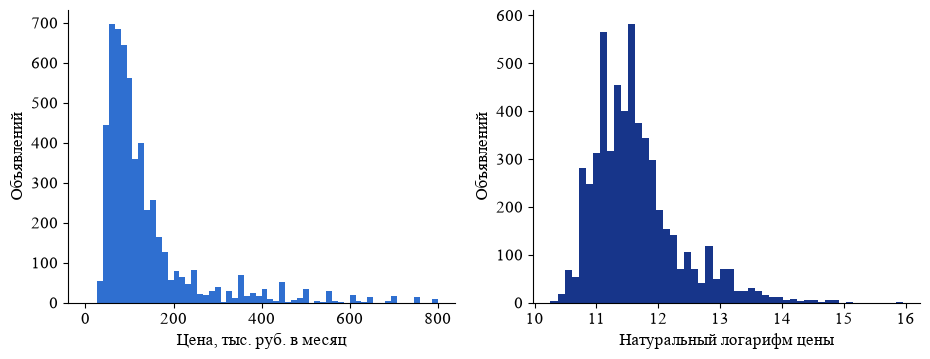

In [4]:
# Асимметрия цены и её логарифма
print("Средняя:", round(df.price.mean()), "медиана:", round(df.price.median()))
print("Асимметрия цены:", round(df.price.skew(), 2), "логарифма:", round(np.log(df.price).skew(), 2))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].hist(df.price / 1000, bins=60, range=(0, 800), color=BLUE)
ax[0].set(xlabel="Цена, тыс. руб. в месяц", ylabel="Объявлений")
ax[1].hist(np.log(df.price), bins=50, color=NAVY)
ax[1].set(xlabel="Натуральный логарифм цены", ylabel="Объявлений")
fig.savefig(FIG / "price_distribution.png")

In [5]:
# Межквартильный размах на цене и на логарифме цены
q1, q3 = df.price.quantile([.25, .75])
print("По цене: граница", round(q3 + 1.5 * (q3 - q1)), "выбросов", int((df.price > q3 + 1.5 * (q3 - q1)).sum()))
l = np.log(df.price); a, b = l.quantile([.25, .75]); low, high = a - 1.5 * (b - a), b + 1.5 * (b - a)
print("По логарифму: границы", round(np.exp(low)), round(np.exp(high)), "выбросов", int(((l < low) | (l > high)).sum()))

По цене: граница 270000 выбросов 603
По логарифму: границы 22316 470523 выбросов 264


dist_center_km   -0.64
metro_minutes    -0.34
built_year        0.01
floor             0.18
floors_total      0.20
area_kitchen      0.49
rooms             0.55
area_total        0.71
price             1.00


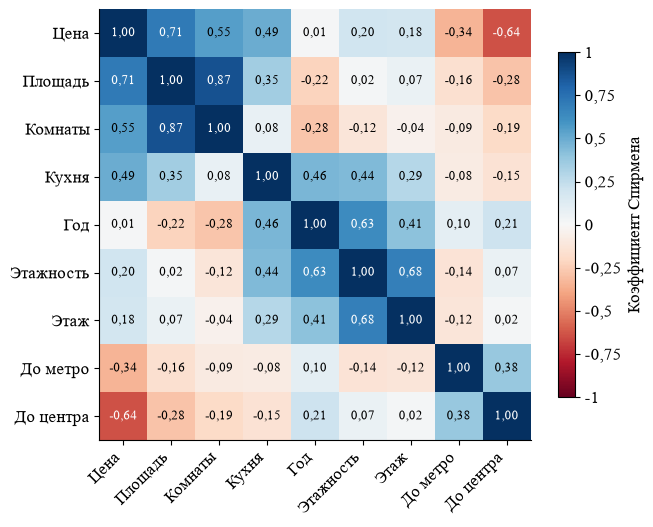

In [6]:
# Корреляция Спирмена
cols = ["price", "area_total", "rooms", "area_kitchen", "built_year", "floors_total", "floor", "metro_minutes", "dist_center_km"]
names = ["Цена", "Площадь", "Комнаты", "Кухня", "Год", "Этажность", "Этаж", "До метро", "До центра"]
corr = df[cols].corr(method="spearman")
print(corr["price"].round(2).sort_values().to_string())
fig, ax = plt.subplots(figsize=(7, 5.6))
im = ax.imshow(corr, cmap="RdBu", vmin=-1, vmax=1)
ax.set_xticks(range(len(cols)), names, rotation=45, ha="right"); ax.set_yticks(range(len(cols)), names)
for i in range(len(cols)):
    for j in range(len(cols)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}".replace(".", ","), ha="center", va="center", fontsize=9,
                color="white" if abs(corr.iloc[i, j]) > .6 else "black")
fig.colorbar(im, shrink=.8, label="Коэффициент Спирмена", format=COMMA)
fig.savefig(FIG / "correlation.png")

In [7]:
# Медианная цена по группам
print(df.groupby("rooms").price.agg(["count", "median"]).round().head(6).to_string())
print(df.groupby(df.renovation.fillna("не указан")).price.agg(["count", "median"]).sort_values("median").to_string())
print(df.groupby(df.building_type.fillna("не указан")).agg(n=("price", "count"), price=("price", "median"), dist=("dist_center_km", "median")).sort_values("price").to_string())
print(df.groupby("metro_transport").price.agg(["count", "median"]).to_string())
print(df.groupby(pd.cut(df.dist_center_km, [0, 5, 15, 100])).apply(lambda g: (g.price / g.area_total).median()).round().to_string())

       count    median
rooms                 
0        810   71400.0
1       1693   80000.0
2       1694  100500.0
3        943  144500.0
4        305  350000.0
5         92  499500.0
                     count    median
renovation                          
COSMETIC_REQUIRED        1   39900.0
PRIME_RENOVATION         2   40000.0
GOOD                    23   60000.0
RENOVATED                9   60500.0
NEEDS_RENOVATION        30   61000.0
COSMETIC_DONE          858   65000.0
EURO                  2471   97000.0
DESIGNER_RENOVATION   1421  139000.0
не указан              772  180000.0
                  n     price   dist
building_type                       
PANEL          1173   70000.0  13.66
BLOCK           205   73000.0   9.40
не указан       463  100000.0  10.37
BRICK           919  110000.0   4.69
MONOLIT        2669  120000.0   8.69
FERROCONCRETE     1  120000.0  10.73
MONOLIT_BRICK   157  140000.0   7.47
                 count    median
metro_transport                 
ON_FOOT   

         n     price  dist
okrug                     
ТАО     62   45000.0  31.4
ЗелАО   39   54900.0  37.5
НАО    372   60000.0  23.6
OTHER    1   60000.0  20.6
ВАО    331   70000.0  10.7
ЮВАО   608   80000.0   7.9
ЮАО    478   85000.0   8.9
СВАО   478   85650.0  10.6
ЮЗАО   324   90000.0  11.6
САО    565  100000.0  10.2
СЗАО   382  110000.0  10.2
ЗАО    751  113000.0  11.6
ЦАО    822  180000.0   3.6


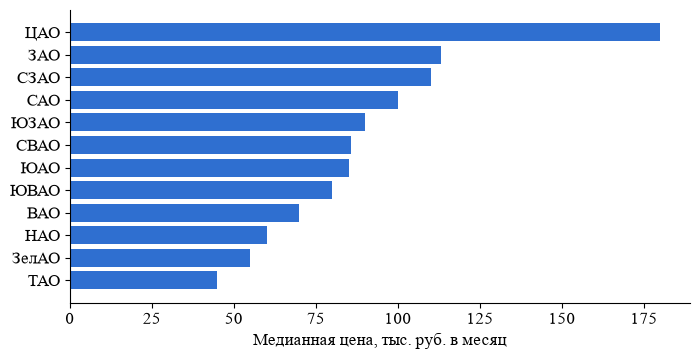

In [8]:
# Цена по округам: округ вычислен в золотом слое по координатам
gold = pd.read_csv(ROOT / "data" / "gold" / "offers_gold.csv", encoding="utf-8-sig")
table = gold.groupby("okrug").agg(n=("price", "count"), price=("price", "median"), dist=("dist_center_km", "median")).sort_values("price")
print(table.round(1).to_string())
part = table[table.index != "OTHER"]
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.barh(part.index, part.price / 1000, color=BLUE)
ax.set(xlabel="Медианная цена, тыс. руб. в месяц")
fig.savefig(FIG / "price_by_okrug.png")

In [9]:
# Ценовые классы: границы и состав
meta = json.loads((ROOT / "data" / "gold" / "gold_meta.json").read_text(encoding="utf-8"))
print(meta)
print(gold.groupby(["split", "price_class"]).agg(n=("price", "count"), price=("price", "median"), area=("area_total", "median"), dist=("dist_center_km", "median")).round(1).to_string())

{'price_low': 22315.581668089744, 'price_high': 470523.24945732806, 'class_bounds': [70000.0, 95000.0, 140000.0], 'class_names': ['Эконом', 'Средний', 'Комфорт', 'Премиум']}
                      n     price  area  dist
split price_class                            
test  0             323   56500.0  36.0  14.0
      1             287   80000.0  40.0  11.4
      2             318  110000.0  48.0   8.3
      3             303  170000.0  69.4   5.7
train 0             986   55500.0  36.0  15.4
      1             917   80000.0  41.0  11.1
      2            1035  110000.0  48.0   8.7
      3            1044  194500.0  75.0   5.4


In [10]:
# Журнал подготовки золотого слоя
import io, contextlib
from preprocess import DataPreprocessor
p = DataPreprocessor()
buffer = io.StringIO()
with contextlib.redirect_stdout(buffer):
    p.clean(p.load())
for name, n in p.steps:
    print(f"{name:45} {n}")
print("после удаления выбросов цены", len(gold), "обучение", (gold.split == "train").sum(), "тест", (gold.split == "test").sum())
print("общих домов в обучении и тесте:", len(set(gold[gold.split == "train"].building_key) & set(gold[gold.split == "test"].building_key)))

загружено из серебряного слоя                 5972
после исключения Московской области           5587
после удаления повторов                       5490
после удаления логических ошибок              5489
после удаления ошибочных площадей и окраин    5432
после удаления строк без этажа и метро        5428
после удаления выбросов цены 5213 обучение 3982 тест 1231
общих домов в обучении и тесте: 0
